# Experiment 6: Compressing NIII, the big network (and the whole pipeline at 4 bit)
**Forhad Islam.** Trained on my RTX 3090 on 17 and 18 October.

NIII has **14.6 million weights (58 MB)**, about 500 times more than the LLE.
* **Part 1:** INT8 and INT4 with no retraining, then INT4 with **distillation**: a 4 bit student copies the full precision teacher. Its practice images are built from the **Glasgow** camera images, so Dr Li's test images stay unseen. One variant also keeps the first and last layers at 8 bit. Finally, the **whole pipeline** at 4 bit (my V4 LLE plus the 4 bit NIII).
* **Part 2:** all three techniques together (distillation, learned scales, first and last layers at 8 bit).

| NIII version | Size | Synthetic | Real HEK293 |
|---|---|---|---|
| His original | 58 MB | 0.161 ns | 0.134 ns |
| INT8, no retraining | 15 MB | 0.161 ns | 0.134 ns |
| INT4, no retraining | 7.3 MB | 0.294 ns | 0.157 ns |
| INT4 + distillation, first/last 8 bit | about 7.3 MB | 0.158 ns | 0.129 ns |
| **Whole pipeline at 4 bit** | **about 7.3 MB** | **0.160 ns** | **0.141 ns** |

**RETRAIN switch:** distillation takes about 2 hours. With `RETRAIN = False` (default), all the code is shown, INT8 and INT4 are computed fresh, and the distilled students **my GPU already trained** are loaded and scored. Set `RETRAIN = True` to train them again (overwrites the saved models).

**Part 3** re-scores every saved model (LLE and NIII) in one table, with the exact numbers from my write up.

In [1]:
import os, sys, glob, subprocess, warnings
warnings.filterwarnings("ignore")
HERE = os.getcwd()                                                       # this experiment's folder
BASE = HERE                                                          # find the University of Strathclyde folder (works at any depth)
while not os.path.isdir(os.path.join(BASE, "04_Shared_Code_and_Data")) and os.path.dirname(BASE) != BASE:
    BASE = os.path.dirname(BASE)
CODE = os.path.join(BASE, "04_Shared_Code_and_Data", "Dr_Li_FPFLI_code")  # Dr Li's FPFLI code, models and sample data
DATA = os.path.join(BASE, "04_Shared_Code_and_Data", "Datasets")
GLASGOW = os.path.join(DATA, "SPAD_FLIM_Glasgow_Zickus2020",
    "DATA_REPOSITORY_fluorescence_lifetime_imaging_with_a_megapixel_SPAD_camera_and_neural_network_lifetime_estimation")
try:
    import mat73
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "mat73"], check=True); import mat73
sys.path.insert(0, CODE); os.chdir(CODE)     # Dr Li's code uses paths like sample_data/... and ./model_parameters/...
import torch
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NONE")
print("results will be saved in:", HERE)

RETRAIN = False   # True = run the distillation training again (about 2 hours, overwrites the saved models)

GPU: NVIDIA GeForce RTX 3090
results will be saved in: <project>\03_Experiments\E6_FPFLI_NIII_Compression


## Part 1. NIII at 8 bit, 4 bit, and 4 bit with distillation

**What this code does** (from the script `niii_quant.py`):

```
niii_quant.py  (Forhad: can Dr Li's NIII network be quantised too?)

NIII is the big network in FPFLI (14.6 million weights, 58 MB at FP32). Three steps:
  1. INT8 weights, no retraining (post training quantisation, per output channel, symmetric)
  2. INT4 weights, no retraining
  3. INT4 weights with quantisation aware training and KNOWLEDGE DISTILLATION:
     the 4 bit "student" learns to copy the full precision "teacher" NIII.
     The practice images are NOT Dr Li's test images: they are built from the Glasgow SPAD camera
     intensity images (Zickus et al. 2020) with random lifetime regions, so the test stays fair.
Every version is scored with the FULL FPFLI pipeline on his sample data (his original FP32 LLE),
and finally the best 4 bit NIII is combined with my 4 bit LLE (V4).
Run with run_niii_on_gpu.bat. Results: my_niii_results/
```

### Setup: imports and settings

In [2]:
import os, io as pyio, json, time, copy, zipfile, warnings, argparse
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
import torch.nn.utils.parametrize as P_
warnings.filterwarnings("ignore")
if not hasattr(torch, '_orig_load_saved'):     # patch torch.load only once per notebook
    torch._orig_load_saved = torch.load
    torch.load = lambda *a, **k: torch._orig_load_saved(*a, **{**k, "weights_only": False, "map_location": k.get("map_location", "cpu")})
import scipy.io as sio, mat73
from scipy.ndimage import gaussian_filter
import matplotlib; matplotlib.use("Agg"); import matplotlib.pyplot as plt
import builtins
import Pred_local_lifetime as PLL
from Prep_exp_data import prep_exp_data
from NIII_model import NIII

ap = argparse.ArgumentParser()
ap.add_argument("--steps", type=int, default=6000)
ap.add_argument("--batch", type=int, default=4)
ap.add_argument("--crop", type=int, default=128)
ap.add_argument("--glasgow", default=r"..\..\..\DCS_Quantisation_Mini_Study\datasets\SPAD_FLIM_Glasgow_Zickus2020\DATA_REPOSITORY_fluorescence_lifetime_imaging_with_a_megapixel_SPAD_camera_and_neural_network_lifetime_estimation")
ap.add_argument("--smoke", action="store_true")
args = ap.parse_args(["--glasgow", GLASGOW])
if args.smoke: args.steps, args.batch = 20, 2
DEV = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEV, torch.cuda.get_device_name(0) if DEV.type == "cuda" else "", flush=True)
OUT = os.path.join(HERE, "my_niii_results"); os.makedirs(OUT, exist_ok=True)
T0 = time.time(); PATCH, H = 8, 0.039
_print = builtins.print
def quiet(f, *a, **k):
    builtins.print = lambda *x, **y: None
    try: return f(*a, **k)
    finally: builtins.print = _print

Device: cuda NVIDIA GeForce RTX 3090


### Quantisation helpers

In [3]:
class FakeQuant(nn.Module):
    def __init__(self, bits): super().__init__(); self.qmax = 2 ** (bits - 1) - 1
    def forward(self, w):
        flat = w.reshape(w.shape[0], -1)
        s = flat.abs().max(1, keepdim=True).values.clamp(min=1e-12) / self.qmax
        q = (torch.round(flat / s).clamp(-self.qmax, self.qmax) * s).reshape(w.shape)
        return w + (q - w).detach()

def qlayers(m):
    return [(n, mod) for n, mod in m.named_modules() if isinstance(mod, (nn.Conv2d, nn.Linear))]

def ptq(model, bits):
    m = copy.deepcopy(model)
    with torch.no_grad():
        for _, mod in qlayers(m): mod.weight.copy_(FakeQuant(bits)(mod.weight))
    return m

teacher = NIII(); teacher.load_state_dict(torch.load("./model_parameters/NIII_parameter_L8.pth.tar")["model"]); teacher.to(DEV).eval()
NW = sum(mod.weight.numel() for _, mod in qlayers(teacher))
print(f"NIII weights: {NW:,} ({NW * 4 / 1e6:.1f} MB at FP32)", flush=True)

def to_dev(d): return {k: (v.to(DEV) if torch.is_tensor(v) else v) for k, v in d.items()}

def niii_apply(model, mask, lr):
    d = to_dev(prep_exp_data(mask.astype("float32"), lr.astype("float32")).prep_data())
    with torch.no_grad():
        p = model(d) * d["lr_tau_max"]
    B, C, Hh, Ww = d["hr_int"].shape
    out = p.reshape(Hh, Ww).cpu().numpy(); out[out < 0] = 0
    return out

NIII weights: 14,553,600 (58.2 MB at FP32)


### His test data through his FP32 LLE (fixed)

In [4]:
def lle(hist, irf, path):
    inten = hist.sum(2); keep = inten > 3
    hm = hist * keep[..., None]; mask = inten * keep
    return quiet(lambda: PLL.Pred_local_lifetime(hm, irf, scaling_ratio=PATCH, h=H, file_path=path).eval_local_tau()), mask

irf_g = sio.loadmat("sample_data/irf_gaussian.mat")["irf_gaussian"].astype("float32")
TESTS = []
for s in (["3"] if args.smoke else ["1", "2", "3", "4", "5", "6"]):
    d = sio.loadmat(f"sample_data/{s}.mat")
    TESTS.append((f"synthetic {s}", d["Hist"].astype("float32"), irf_g, d["tau_gt"].astype("float32"), "general"))
d = sio.loadmat("sample_data/hek_low.mat")
TESTS.append(("HEK293", d["hist"].astype("float32"), d["irf"].astype("float32"), mat73.loadmat("sample_data/hek_gt.mat")["tau_img_gt"].astype("float32"), "1-3ns"))
LLE_FILES = {"FP32": {"general": "./model_parameters/LLE_parameter.pth", "1-3ns": "./model_parameters/LLE_parameter_1_3ns.pth"},
             "V4 4 bit": {"general": "./model_parameters/LLE_parameter_V4.pth", "1-3ns": "./model_parameters/LLE_parameter_1_3ns_V4.pth"}}
LR = {}
for lname, files in LLE_FILES.items():
    if not all(os.path.exists(f) for f in files.values()): continue
    LR[lname] = [lle(h, i, files[kind]) for _, h, i, _, kind in TESTS]

def score(model, lname="FP32", keep=False):
    res, imgs = {}, {}
    for (name, _, _, gt, _), (lr, mask) in zip(TESTS, LR[lname]):
        p = niii_apply(model, mask, lr); k = (mask > 0) & (gt > 0)
        res[name] = float(np.mean(np.abs(p[k] - gt[k])))
        if keep: imgs[name] = p
    syn = [v for k, v in res.items() if k.startswith("synthetic")]
    res["synthetic mean"] = float(np.mean(syn))
    return (res, imgs) if keep else res

R = {}; SHOW = {}
for name, m in [("FP32 (original)", teacher), ("INT8 plain", ptq(teacher, 8)), ("INT4 plain", ptq(teacher, 4))]:
    R[name], im = score(m, keep=True); SHOW[name] = im
    print(f"{name:28s} synthetic {R[name]['synthetic mean']:.3f} ns  HEK293 {R[name]['HEK293']:.3f} ns ({time.time() - T0:.0f} s)", flush=True)

FP32 (original)              synthetic 0.161 ns  HEK293 0.134 ns (3 s)
INT8 plain                   synthetic 0.161 ns  HEK293 0.134 ns (4 s)
INT4 plain                   synthetic 0.294 ns  HEK293 0.157 ns (4 s)


### Distillation practice images (Glasgow intensities)

In [5]:
def glasgow_intensity(zname, inner):
    plain = os.path.join(args.glasgow, "data", "05_Experiment_processed_data", inner)
    if os.path.exists(plain): c = np.load(plain, mmap_mode="r")
    else:
        with zipfile.ZipFile(os.path.join(args.glasgow, "data", "05_Experiment_processed_data", zname)) as z:
            c = np.load(pyio.BytesIO(z.read(inner)))
    out = np.zeros(c.shape[:2], "float32")
    for i in range(0, c.shape[0], 50):
        out[i:i + 50] = np.nan_to_num(np.asarray(c[i:i + 50], dtype="float32"), nan=0, posinf=0, neginf=0).clip(0).sum(-1)
    return out

cache = os.path.join(HERE, "distill_intensity_cache_smoke.npz" if args.smoke else "distill_intensity_cache.npz")
if os.path.exists(cache):
    SRC = list(np.load(cache).values())
else:
    SRC = [glasgow_intensity("HPC.zip", "HPC/speed_shift504_exp3300_location1.npy"),
           glasgow_intensity("LPC.zip", "LPC/speed_shift504_exp330_location1.npy")]
    if not args.smoke: SRC.append(glasgow_intensity("HT1080.zip", "HT1080/ht1080_9bit.npy"))
    np.savez(cache, *SRC)
print(f"practice images ready: {[s.shape for s in SRC]} ({time.time() - T0:.0f} s)", flush=True)
rng = np.random.default_rng(0)

def practice_sample(c=args.crop):
    src = SRC[rng.integers(len(SRC))]
    for _ in range(20):
        y, x = rng.integers(0, src.shape[0] - c), rng.integers(0, src.shape[1] - c)
        im = src[y:y + c, x:x + c].copy()
        if (im > np.percentile(src, 60)).mean() > 0.15: break
    if rng.random() < .5: im = im[::-1]
    if rng.random() < .5: im = im[:, ::-1]
    im = im / (np.percentile(im, 99) + 1e-6) * rng.uniform(8, 40)          # photons per pixel like his images
    inten = rng.poisson(im.clip(0)).astype("float32")
    mask = inten * (inten > 3)
    sm = gaussian_filter(im, 2); k = rng.integers(2, 6)
    levels = np.digitize(sm, np.quantile(sm, np.linspace(0, 1, k + 1)[1:-1]))
    tau = rng.uniform(0.5, 4.0, k)[levels] + gaussian_filter(rng.standard_normal(im.shape), 15) * 2
    tau = tau.clip(0.2, 5.0)
    m = mask > 0
    s_ = (tau * m).reshape(c // 8, 8, c // 8, 8).sum((1, 3)); n_ = m.reshape(c // 8, 8, c // 8, 8).sum((1, 3))
    lr = np.where(n_ >= 4, s_ / np.maximum(n_, 1) + rng.normal(0, 0.05, n_.shape), 0).clip(0).astype("float32")
    if lr.max() <= 0: return practice_sample(c)
    return prep_exp_data(mask.astype("float32"), lr).prep_data()

practice images ready: [(500, 1024), (500, 1024), (500, 1024)] (4 s)


In [6]:
def batch_of(n):
    ds = [practice_sample() for _ in range(n)]
    return {k: (torch.cat([d[k] for d in ds]).to(DEV) if torch.is_tensor(ds[0][k]) else None) for k in ds[0] if k != "lr_tau_max"}

### 4 bit QAT with distillation

In [7]:
def distil(bits_map, tag):
    student = copy.deepcopy(teacher).train()
    for n, mod in qlayers(student): P_.register_parametrization(mod, "weight", FakeQuant(bits_map(n)))
    opt = torch.optim.Adam(student.parameters(), lr=2e-5)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, args.steps)
    run = 0
    for step in range(1, args.steps + 1):
        b = batch_of(args.batch)
        with torch.no_grad(): t = teacher(b)
        loss = F.l1_loss(student(b), t)
        opt.zero_grad(); loss.backward(); opt.step(); sched.step()
        run = 0.98 * run + 0.02 * loss.item() if step > 1 else loss.item()
        if step % 500 == 0 or step == args.steps:
            print(f"[{tag}] step {step}/{args.steps} distillation loss {run:.5f} ({time.time() - T0:.0f} s)", flush=True)
    for n, mod in qlayers(student): P_.remove_parametrizations(mod, "weight", leave_parametrized=True)
    student.eval()
    torch.save({"model": student.state_dict()}, f"./model_parameters/NIII_parameter_L8_{tag}.pth.tar")
    return student

def load_saved(tag):
    m = NIII(); m.load_state_dict(torch.load(f"./model_parameters/NIII_parameter_L8_{tag}.pth.tar")["model"]); return m.to(DEV).eval()

names = [n for n, _ in qlayers(teacher)]
first_last = {names[0], names[-1], "int_encoder.sfe1", "tau_encoder.sfe1"}
VARIANTS = [("INT4 + distillation", lambda n: 4, "INT4_distil"),
            ("INT4 + distillation, first/last layers 8 bit", lambda n: 8 if n in first_last else 4, "INT4mixed_distil")]
for label, bm, tag in VARIANTS:
    stu = distil(bm, tag) if RETRAIN else load_saved(tag)
    R[label], im = score(stu, keep=True); SHOW[label] = im
    print(f"{label:28s} synthetic {R[label]['synthetic mean']:.3f} ns  HEK293 {R[label]['HEK293']:.3f} ns ({time.time() - T0:.0f} s)", flush=True)
    if "V4 4 bit" in LR:
        key = f"whole pipeline 4 bit: LLE V4 + NIII {label}"
        R[key] = score(stu, "V4 4 bit")
        print(f"{key}: synthetic {R[key]['synthetic mean']:.3f} ns  HEK293 {R[key]['HEK293']:.3f} ns", flush=True)

R["memory MB (NIII weights)"] = {"FP32": NW * 4 / 1e6, "INT8": NW / 1e6, "INT4": NW / 2 / 1e6}
json.dump(R, open(f"{OUT}/niii_results.json", "w"), indent=2)

INT4 + distillation          synthetic 0.162 ns  HEK293 0.129 ns (5 s)
whole pipeline 4 bit: LLE V4 + NIII INT4 + distillation: synthetic 0.163 ns  HEK293 0.142 ns
INT4 + distillation, first/last layers 8 bit synthetic 0.158 ns  HEK293 0.129 ns (7 s)
whole pipeline 4 bit: LLE V4 + NIII INT4 + distillation, first/last layers 8 bit: synthetic 0.160 ns  HEK293 0.141 ns


### Figures

In [8]:
labels = [k for k in R if not k.startswith("whole") and not k.startswith("memory")]
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for a, key, t in [(ax[0], "synthetic mean", "His 6 synthetic images, mean error"), (ax[1], "HEK293", "Real HEK293 cells, error")]:
    v = [R[l][key] for l in labels]
    bars = a.bar(range(len(v)), v, color=["#7f8c8d", "#2980b9", "#c0392b", "#27ae60", "#16a085"][:len(v)])
    a.set_xticks(range(len(v))); a.set_xticklabels([l.replace(", ", "\n").replace(" + ", "\n+ ") for l in labels], fontsize=7)
    a.set_ylabel("mean absolute error (ns)"); a.set_title(t)
    for b_, x in zip(bars, v): a.text(b_.get_x() + b_.get_width() / 2, x, f"{x:.3f}", ha="center", va="bottom", fontsize=8)
fig.suptitle("Quantising Dr Li's NIII (58 MB): weights only, his FP32 LLE in front")
fig.tight_layout(); fig.savefig(f"{OUT}/fig_niii_summary.png", dpi=130); plt.close(fig)
for test in ["synthetic 3", "HEK293"]:
    if test not in SHOW[labels[0]]: continue
    gt = [t[3] for t in TESTS if t[0] == test][0]
    fig, ax = plt.subplots(1, len(labels) + 1, figsize=(3.4 * (len(labels) + 1), 3.6))
    vmax = 4 if test.startswith("syn") else 2.5
    for a, (k, im) in zip(ax, [("truth / reference", gt)] + [(l, SHOW[l][test]) for l in labels]):
        h_ = a.imshow(im, cmap="inferno", vmin=0, vmax=vmax); a.set_title(k.replace(", ", "\n"), fontsize=8); a.axis("off")
    fig.colorbar(h_, ax=ax, shrink=.8, label="lifetime (ns)")
    fig.savefig(f"{OUT}/fig_niii_{test.replace(' ', '')}.png", dpi=110, bbox_inches="tight"); plt.close(fig)
print(f"ALL DONE ({time.time() - T0:.0f} s)", flush=True)

ALL DONE (8 s)


### Figures from Part 1

fig_niii_HEK293.png


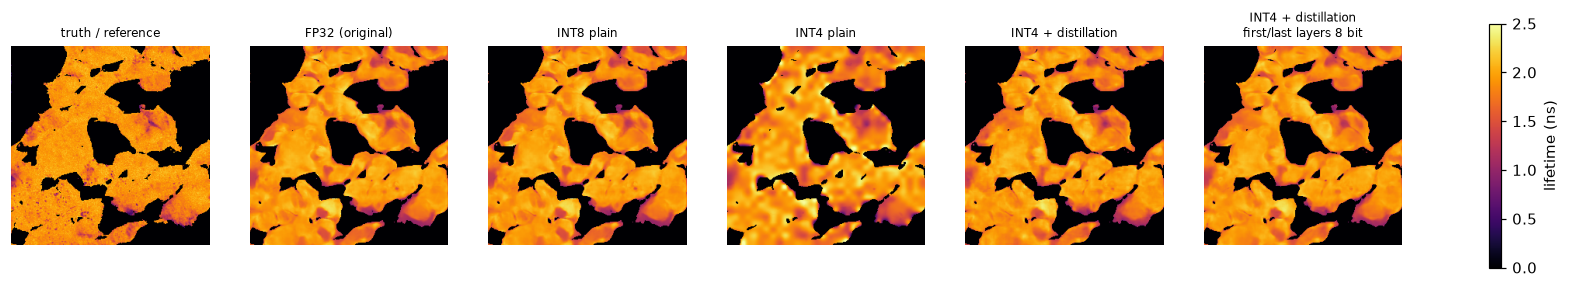

fig_niii_summary.png


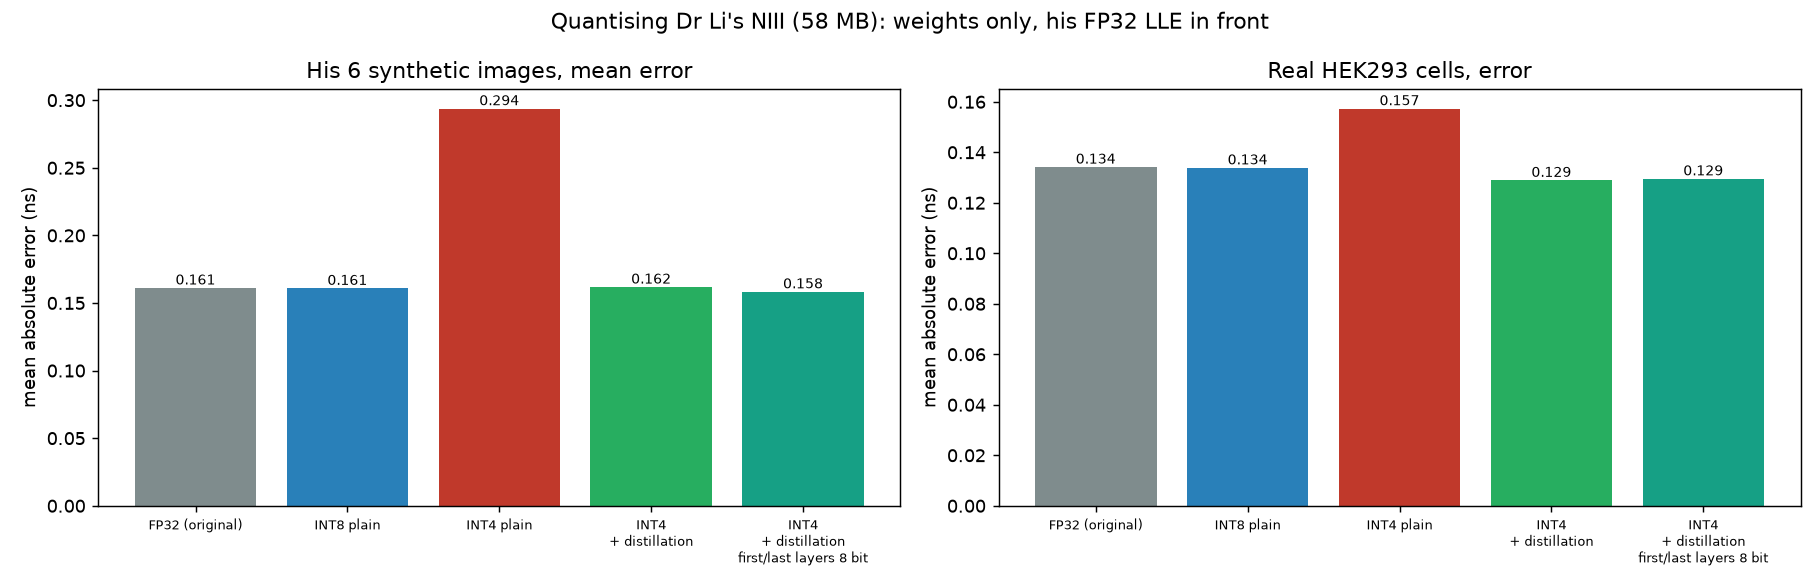

fig_niii_synthetic3.png


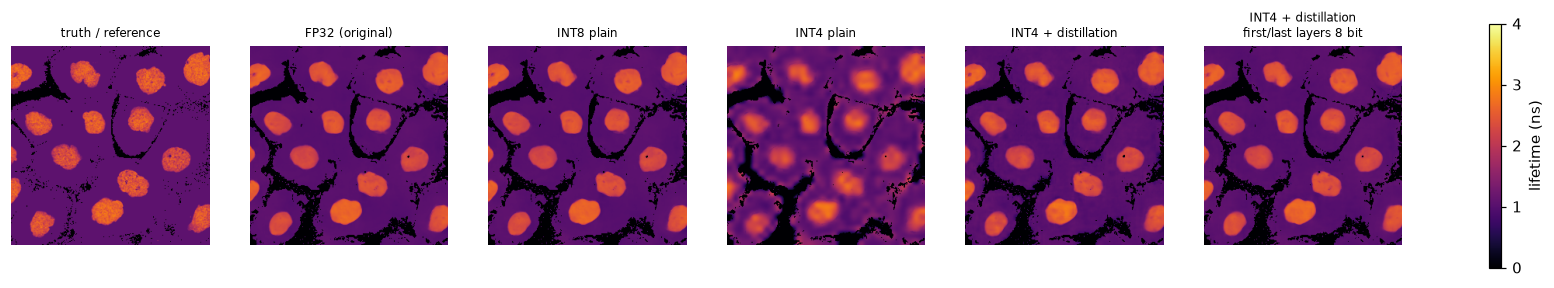

In [9]:
from IPython.display import Image, display
for f in sorted(glob.glob(os.path.join(OUT, "*.png"))):
    print(os.path.basename(f)); display(Image(filename=f, width=950))

## Part 2. All three techniques together

**What this code does** (from the script `niii_quant_all3.py`):

```
niii_quant_all3.py  (Forhad: NIII at 4 bit with ALL THREE techniques: distillation + learned scales (LSQ) + first/last layers 8 bit)

Based on niii_quant.py (Forhad: can Dr Li's NIII network be quantised too?)

NIII is the big network in FPFLI (14.6 million weights, 58 MB at FP32). Three steps:
  1. INT8 weights, no retraining (post training quantisation, per output channel, symmetric)
  2. INT4 weights, no retraining
  3. INT4 weights with quantisation aware training and KNOWLEDGE DISTILLATION:
     the 4 bit "student" learns to copy the full precision "teacher" NIII.
     The practice images are NOT Dr Li's test images: they are built from the Glasgow SPAD camera
     intensity images (Zickus et al. 2020) with random lifetime regions, so the test stays fair.
Every version is scored with the FULL FPFLI pipeline on his sample data (his original FP32 LLE),
and finally the best 4 bit NIII is combined with my 4 bit LLE (V4).
Run with run_niii_on_gpu.bat. Results: my_niii_results/
```

### Setup: imports and settings

In [10]:
import os, io as pyio, json, time, copy, zipfile, warnings, argparse
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
import torch.nn.utils.parametrize as P_
warnings.filterwarnings("ignore")
if not hasattr(torch, '_orig_load_saved'):     # patch torch.load only once per notebook
    torch._orig_load_saved = torch.load
    torch.load = lambda *a, **k: torch._orig_load_saved(*a, **{**k, "weights_only": False, "map_location": k.get("map_location", "cpu")})
import scipy.io as sio, mat73
from scipy.ndimage import gaussian_filter
import matplotlib; matplotlib.use("Agg"); import matplotlib.pyplot as plt
import builtins
import Pred_local_lifetime as PLL
from Prep_exp_data import prep_exp_data
from NIII_model import NIII

ap = argparse.ArgumentParser()
ap.add_argument("--steps", type=int, default=6000)
ap.add_argument("--batch", type=int, default=4)
ap.add_argument("--crop", type=int, default=128)
ap.add_argument("--glasgow", default=r"..\..\..\DCS_Quantisation_Mini_Study\datasets\SPAD_FLIM_Glasgow_Zickus2020\DATA_REPOSITORY_fluorescence_lifetime_imaging_with_a_megapixel_SPAD_camera_and_neural_network_lifetime_estimation")
ap.add_argument("--smoke", action="store_true")
args = ap.parse_args(["--glasgow", GLASGOW])
if args.smoke: args.steps, args.batch = 20, 2
DEV = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEV, torch.cuda.get_device_name(0) if DEV.type == "cuda" else "", flush=True)
OUT = os.path.join(HERE, "my_niii_all3_results"); os.makedirs(OUT, exist_ok=True)
T0 = time.time(); PATCH, H = 8, 0.039
_print = builtins.print
def quiet(f, *a, **k):
    builtins.print = lambda *x, **y: None
    try: return f(*a, **k)
    finally: builtins.print = _print

Device: cuda NVIDIA GeForce RTX 3090


### Quantisation helpers

In [11]:
class FakeQuant(nn.Module):
    def __init__(self, bits): super().__init__(); self.qmax = 2 ** (bits - 1) - 1
    def forward(self, w):
        flat = w.reshape(w.shape[0], -1)
        s = flat.abs().max(1, keepdim=True).values.clamp(min=1e-12) / self.qmax
        q = (torch.round(flat / s).clamp(-self.qmax, self.qmax) * s).reshape(w.shape)
        return w + (q - w).detach()

class LSQ(nn.Module):
    """Learned per output channel scale; rounding uses a straight through estimator, the scale gets real gradients."""
    def __init__(self, w, bits):
        super().__init__(); self.qmax = 2 ** (bits - 1) - 1
        init = w.detach().reshape(w.shape[0], -1).abs().max(1).values.clamp(min=1e-8) / self.qmax
        self.log_s = nn.Parameter(init.log())
    def forward(self, w):
        s = self.log_s.exp().view(-1, *([1] * (w.dim() - 1)))
        x = (w / s).clamp(-self.qmax, self.qmax)
        return (x + (torch.round(x) - x).detach()) * s

def qlayers(m):
    return [(n, mod) for n, mod in m.named_modules() if isinstance(mod, (nn.Conv2d, nn.Linear))]

def ptq(model, bits):
    m = copy.deepcopy(model)
    with torch.no_grad():
        for _, mod in qlayers(m): mod.weight.copy_(FakeQuant(bits)(mod.weight))
    return m

teacher = NIII(); teacher.load_state_dict(torch.load("./model_parameters/NIII_parameter_L8.pth.tar")["model"]); teacher.to(DEV).eval()
NW = sum(mod.weight.numel() for _, mod in qlayers(teacher))
print(f"NIII weights: {NW:,} ({NW * 4 / 1e6:.1f} MB at FP32)", flush=True)

def to_dev(d): return {k: (v.to(DEV) if torch.is_tensor(v) else v) for k, v in d.items()}

def niii_apply(model, mask, lr):
    d = to_dev(prep_exp_data(mask.astype("float32"), lr.astype("float32")).prep_data())
    with torch.no_grad():
        p = model(d) * d["lr_tau_max"]
    B, C, Hh, Ww = d["hr_int"].shape
    out = p.reshape(Hh, Ww).cpu().numpy(); out[out < 0] = 0
    return out

NIII weights: 14,553,600 (58.2 MB at FP32)


### His test data through his FP32 LLE (fixed)

In [12]:
def lle(hist, irf, path):
    inten = hist.sum(2); keep = inten > 3
    hm = hist * keep[..., None]; mask = inten * keep
    return quiet(lambda: PLL.Pred_local_lifetime(hm, irf, scaling_ratio=PATCH, h=H, file_path=path).eval_local_tau()), mask

irf_g = sio.loadmat("sample_data/irf_gaussian.mat")["irf_gaussian"].astype("float32")
TESTS = []
for s in (["3"] if args.smoke else ["1", "2", "3", "4", "5", "6"]):
    d = sio.loadmat(f"sample_data/{s}.mat")
    TESTS.append((f"synthetic {s}", d["Hist"].astype("float32"), irf_g, d["tau_gt"].astype("float32"), "general"))
d = sio.loadmat("sample_data/hek_low.mat")
TESTS.append(("HEK293", d["hist"].astype("float32"), d["irf"].astype("float32"), mat73.loadmat("sample_data/hek_gt.mat")["tau_img_gt"].astype("float32"), "1-3ns"))
LLE_FILES = {"FP32": {"general": "./model_parameters/LLE_parameter.pth", "1-3ns": "./model_parameters/LLE_parameter_1_3ns.pth"},
             "V4 4 bit": {"general": "./model_parameters/LLE_parameter_V4.pth", "1-3ns": "./model_parameters/LLE_parameter_1_3ns_V4.pth"}}
LR = {}
for lname, files in LLE_FILES.items():
    if not all(os.path.exists(f) for f in files.values()): continue
    LR[lname] = [lle(h, i, files[kind]) for _, h, i, _, kind in TESTS]

def score(model, lname="FP32", keep=False):
    res, imgs = {}, {}
    for (name, _, _, gt, _), (lr, mask) in zip(TESTS, LR[lname]):
        p = niii_apply(model, mask, lr); k = (mask > 0) & (gt > 0)
        res[name] = float(np.mean(np.abs(p[k] - gt[k])))
        if keep: imgs[name] = p
    syn = [v for k, v in res.items() if k.startswith("synthetic")]
    res["synthetic mean"] = float(np.mean(syn))
    return (res, imgs) if keep else res

R = {}; SHOW = {}
for name, m in [("FP32 (original)", teacher), ("INT8 plain", ptq(teacher, 8)), ("INT4 plain", ptq(teacher, 4))]:
    R[name], im = score(m, keep=True); SHOW[name] = im
    print(f"{name:28s} synthetic {R[name]['synthetic mean']:.3f} ns  HEK293 {R[name]['HEK293']:.3f} ns ({time.time() - T0:.0f} s)", flush=True)

FP32 (original)              synthetic 0.161 ns  HEK293 0.134 ns (3 s)
INT8 plain                   synthetic 0.161 ns  HEK293 0.134 ns (3 s)
INT4 plain                   synthetic 0.294 ns  HEK293 0.157 ns (4 s)


### Distillation practice images (Glasgow intensities)

In [13]:
def glasgow_intensity(zname, inner):
    plain = os.path.join(args.glasgow, "data", "05_Experiment_processed_data", inner)
    if os.path.exists(plain): c = np.load(plain, mmap_mode="r")
    else:
        with zipfile.ZipFile(os.path.join(args.glasgow, "data", "05_Experiment_processed_data", zname)) as z:
            c = np.load(pyio.BytesIO(z.read(inner)))
    out = np.zeros(c.shape[:2], "float32")
    for i in range(0, c.shape[0], 50):
        out[i:i + 50] = np.nan_to_num(np.asarray(c[i:i + 50], dtype="float32"), nan=0, posinf=0, neginf=0).clip(0).sum(-1)
    return out

cache = os.path.join(HERE, "distill_intensity_cache_smoke.npz" if args.smoke else "distill_intensity_cache.npz")
if os.path.exists(cache):
    SRC = list(np.load(cache).values())
else:
    SRC = [glasgow_intensity("HPC.zip", "HPC/speed_shift504_exp3300_location1.npy"),
           glasgow_intensity("LPC.zip", "LPC/speed_shift504_exp330_location1.npy")]
    if not args.smoke: SRC.append(glasgow_intensity("HT1080.zip", "HT1080/ht1080_9bit.npy"))
    np.savez(cache, *SRC)
print(f"practice images ready: {[s.shape for s in SRC]} ({time.time() - T0:.0f} s)", flush=True)
rng = np.random.default_rng(0)

def practice_sample(c=args.crop):
    src = SRC[rng.integers(len(SRC))]
    for _ in range(20):
        y, x = rng.integers(0, src.shape[0] - c), rng.integers(0, src.shape[1] - c)
        im = src[y:y + c, x:x + c].copy()
        if (im > np.percentile(src, 60)).mean() > 0.15: break
    if rng.random() < .5: im = im[::-1]
    if rng.random() < .5: im = im[:, ::-1]
    im = im / (np.percentile(im, 99) + 1e-6) * rng.uniform(8, 40)          # photons per pixel like his images
    inten = rng.poisson(im.clip(0)).astype("float32")
    mask = inten * (inten > 3)
    sm = gaussian_filter(im, 2); k = rng.integers(2, 6)
    levels = np.digitize(sm, np.quantile(sm, np.linspace(0, 1, k + 1)[1:-1]))
    tau = rng.uniform(0.5, 4.0, k)[levels] + gaussian_filter(rng.standard_normal(im.shape), 15) * 2
    tau = tau.clip(0.2, 5.0)
    m = mask > 0
    s_ = (tau * m).reshape(c // 8, 8, c // 8, 8).sum((1, 3)); n_ = m.reshape(c // 8, 8, c // 8, 8).sum((1, 3))
    lr = np.where(n_ >= 4, s_ / np.maximum(n_, 1) + rng.normal(0, 0.05, n_.shape), 0).clip(0).astype("float32")
    if lr.max() <= 0: return practice_sample(c)
    return prep_exp_data(mask.astype("float32"), lr).prep_data()

practice images ready: [(500, 1024), (500, 1024), (500, 1024)] (4 s)


In [14]:
def batch_of(n):
    ds = [practice_sample() for _ in range(n)]
    return {k: (torch.cat([d[k] for d in ds]).to(DEV) if torch.is_tensor(ds[0][k]) else None) for k in ds[0] if k != "lr_tau_max"}

### 4 bit QAT with distillation

In [15]:
def distil(bits_map, tag):
    student = copy.deepcopy(teacher).train()
    for n, mod in qlayers(student): P_.register_parametrization(mod, "weight", LSQ(mod.weight, bits_map(n)))
    sc = [p for n, p in student.named_parameters() if n.endswith("log_s")]
    ot = [p for n, p in student.named_parameters() if not n.endswith("log_s")]
    opt = torch.optim.Adam([{"params": ot, "lr": 2e-5}, {"params": sc, "lr": 1e-3}])
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, args.steps)
    run = 0
    for step in range(1, args.steps + 1):
        b = batch_of(args.batch)
        with torch.no_grad(): t = teacher(b)
        loss = F.l1_loss(student(b), t)
        opt.zero_grad(); loss.backward(); opt.step(); sched.step()
        run = 0.98 * run + 0.02 * loss.item() if step > 1 else loss.item()
        if step % 500 == 0 or step == args.steps:
            print(f"[{tag}] step {step}/{args.steps} distillation loss {run:.5f} ({time.time() - T0:.0f} s)", flush=True)
    for n, mod in qlayers(student): P_.remove_parametrizations(mod, "weight", leave_parametrized=True)
    student.eval()
    torch.save({"model": student.state_dict()}, f"./model_parameters/NIII_parameter_L8_{tag}.pth.tar")
    return student

def load_saved(tag):
    m = NIII(); m.load_state_dict(torch.load(f"./model_parameters/NIII_parameter_L8_{tag}.pth.tar")["model"]); return m.to(DEV).eval()

names = [n for n, _ in qlayers(teacher)]
first_last = {names[0], names[-1], "int_encoder.sfe1", "tau_encoder.sfe1"}
VARIANTS = [("INT4 + distillation + learned scales, first/last layers 8 bit", lambda n: 8 if n in first_last else 4, "INT4_all3")]
for label, bm, tag in VARIANTS:
    stu = distil(bm, tag) if RETRAIN else load_saved(tag)
    R[label], im = score(stu, keep=True); SHOW[label] = im
    print(f"{label:28s} synthetic {R[label]['synthetic mean']:.3f} ns  HEK293 {R[label]['HEK293']:.3f} ns ({time.time() - T0:.0f} s)", flush=True)
    if "V4 4 bit" in LR:
        key = f"whole pipeline 4 bit: LLE V4 + NIII {label}"
        R[key] = score(stu, "V4 4 bit")
        print(f"{key}: synthetic {R[key]['synthetic mean']:.3f} ns  HEK293 {R[key]['HEK293']:.3f} ns", flush=True)

R["memory MB (NIII weights)"] = {"FP32": NW * 4 / 1e6, "INT8": NW / 1e6, "INT4": NW / 2 / 1e6}
json.dump(R, open(f"{OUT}/niii_all3_results.json", "w"), indent=2)

INT4 + distillation + learned scales, first/last layers 8 bit synthetic 0.157 ns  HEK293 0.132 ns (5 s)
whole pipeline 4 bit: LLE V4 + NIII INT4 + distillation + learned scales, first/last layers 8 bit: synthetic 0.162 ns  HEK293 0.139 ns


### Figures

In [16]:
labels = [k for k in R if not k.startswith("whole") and not k.startswith("memory")]
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for a, key, t in [(ax[0], "synthetic mean", "His 6 synthetic images, mean error"), (ax[1], "HEK293", "Real HEK293 cells, error")]:
    v = [R[l][key] for l in labels]
    bars = a.bar(range(len(v)), v, color=["#7f8c8d", "#2980b9", "#c0392b", "#27ae60", "#16a085"][:len(v)])
    a.set_xticks(range(len(v))); a.set_xticklabels([l.replace(", ", "\n").replace(" + ", "\n+ ") for l in labels], fontsize=7)
    a.set_ylabel("mean absolute error (ns)"); a.set_title(t)
    for b_, x in zip(bars, v): a.text(b_.get_x() + b_.get_width() / 2, x, f"{x:.3f}", ha="center", va="bottom", fontsize=8)
fig.suptitle("Quantising Dr Li's NIII (58 MB): weights only, his FP32 LLE in front")
fig.tight_layout(); fig.savefig(f"{OUT}/fig_niii_all3_summary.png", dpi=130); plt.close(fig)
for test in ["synthetic 3", "HEK293"]:
    if test not in SHOW[labels[0]]: continue
    gt = [t[3] for t in TESTS if t[0] == test][0]
    fig, ax = plt.subplots(1, len(labels) + 1, figsize=(3.4 * (len(labels) + 1), 3.6))
    vmax = 4 if test.startswith("syn") else 2.5
    for a, (k, im) in zip(ax, [("truth / reference", gt)] + [(l, SHOW[l][test]) for l in labels]):
        h_ = a.imshow(im, cmap="inferno", vmin=0, vmax=vmax); a.set_title(k.replace(", ", "\n"), fontsize=8); a.axis("off")
    fig.colorbar(h_, ax=ax, shrink=.8, label="lifetime (ns)")
    fig.savefig(f"{OUT}/fig_niii_all3_{test.replace(' ', '')}.png", dpi=110, bbox_inches="tight"); plt.close(fig)
print(f"ALL DONE ({time.time() - T0:.0f} s)", flush=True)

ALL DONE (6 s)


### Figures from Part 2

fig_niii_all3_HEK293.png


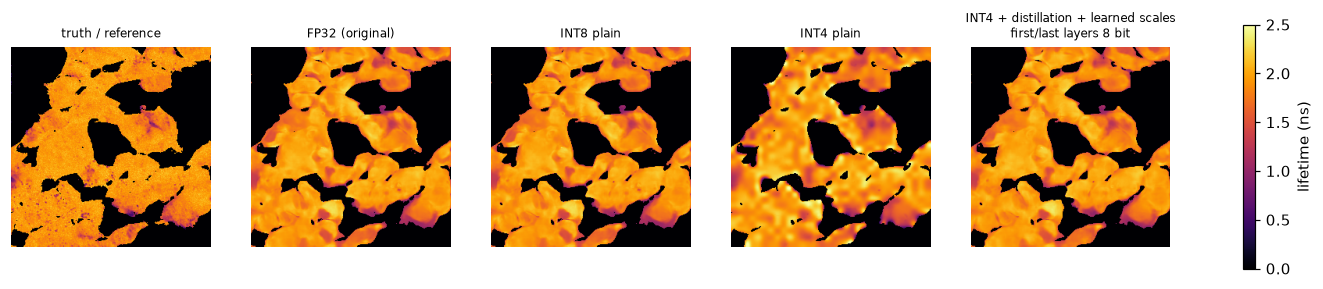

fig_niii_all3_summary.png


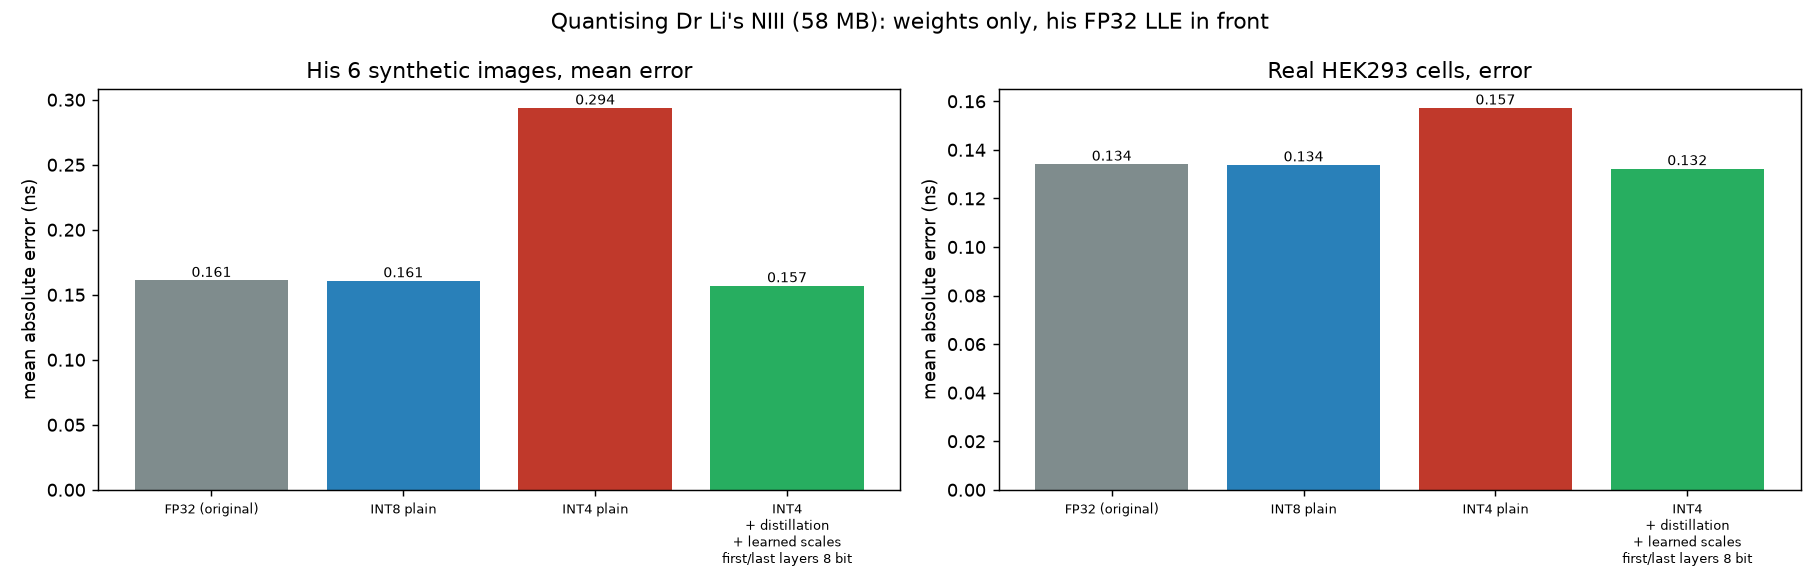

fig_niii_all3_synthetic3.png


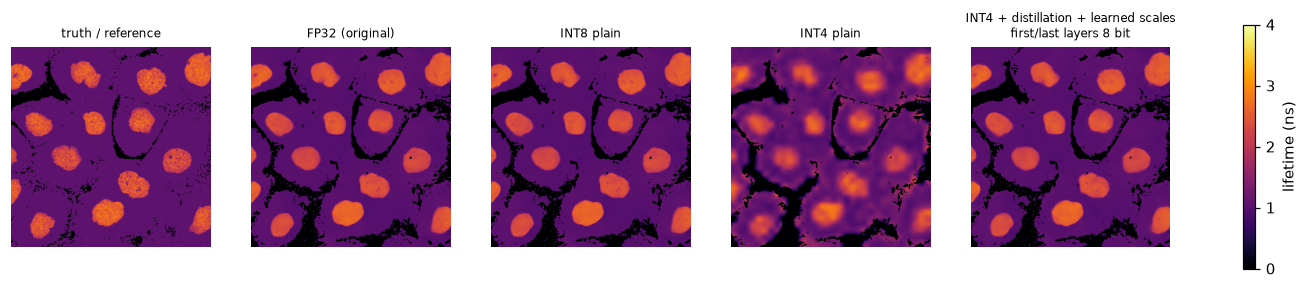

In [17]:
from IPython.display import Image, display
for f in sorted(glob.glob(os.path.join(OUT, "*.png"))):
    print(os.path.basename(f)); display(Image(filename=f, width=950))

## Part 3. Check every saved model in one table

**What this code does** (from the script `eval_saved_models.py`):

```
eval_saved_models.py  (Forhad)

Re-scores ALL the models my RTX 3090 already trained, with Dr Li's full FPFLI pipeline (LLE + NIII)
on his sample data. No training, nothing random, so it reproduces the exact numbers in my write up.

  python eval_saved_models.py          (about 2 to 4 minutes on the GPU)
Output: printed table and my_saved_model_check/saved_model_check.json
```

### Setup: imports and settings

In [18]:
import os, json, time, warnings, builtins
import numpy as np, torch, torch.nn as nn
warnings.filterwarnings("ignore")
if not hasattr(torch, '_orig_load_saved'):     # patch torch.load only once per notebook
    torch._orig_load_saved = torch.load
    torch.load = lambda *a, **k: torch._orig_load_saved(*a, **{**k, "weights_only": False, "map_location": k.get("map_location", "cpu")})
import scipy.io as sio, mat73
import Pred_local_lifetime as PLL
from Prep_exp_data import prep_exp_data
from NIII_model import NIII

DEV = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEV, torch.cuda.get_device_name(0) if DEV.type == "cuda" else "", flush=True)
MP = "./model_parameters/"
OUT = os.path.join(HERE, "my_saved_model_check"); os.makedirs(OUT, exist_ok=True)
_print = builtins.print
def quiet(f, *a, **k):
    builtins.print = lambda *x, **y: None
    try: return f(*a, **k)
    finally: builtins.print = _print

def ptq_(model, bits):
    qmax = 2 ** (bits - 1) - 1
    with torch.no_grad():
        for m in model.modules():
            if isinstance(m, (nn.Conv1d, nn.Conv2d, nn.Linear)):
                f = m.weight.reshape(m.weight.shape[0], -1)
                s = f.abs().max(1, keepdim=True).values.clamp(min=1e-12) / qmax
                m.weight.copy_((torch.round(f / s).clamp(-qmax, qmax) * s).reshape(m.weight.shape))

def load_niii(path, bits=None):
    m = NIII(); m.load_state_dict(torch.load(path)["model"]); m.to(DEV).eval()
    if bits: ptq_(m, bits)
    return m

irf_g = sio.loadmat("sample_data/irf_gaussian.mat")["irf_gaussian"].astype("float32")
TESTS = []
for s in ["1", "2", "3", "4", "5", "6"]:
    d = sio.loadmat(f"sample_data/{s}.mat")
    TESTS.append((f"synthetic {s}", d["Hist"].astype("float32"), irf_g, d["tau_gt"].astype("float32"), "general"))
d = sio.loadmat("sample_data/hek_low.mat")
TESTS.append(("HEK293", d["hist"].astype("float32"), d["irf"].astype("float32"), mat73.loadmat("sample_data/hek_gt.mat")["tau_img_gt"].astype("float32"), "1-3ns"))

LLES = {"LLE FP32 (Dr Li)": ("LLE_parameter.pth", "LLE_parameter_1_3ns.pth", None),
        "LLE INT8 plain": ("LLE_parameter.pth", "LLE_parameter_1_3ns.pth", 8),
        "LLE INT4 plain": ("LLE_parameter.pth", "LLE_parameter_1_3ns.pth", 4),
        "LLE INT4 QAT v1": ("LLE_parameter_QAT_INT4.pth", "LLE_parameter_1_3ns_QAT_INT4.pth", None),
        "LLE INT4 V4 (best)": ("LLE_parameter_V4.pth", "LLE_parameter_1_3ns_V4.pth", None)}

Device: cuda NVIDIA GeForce RTX 3090


In [19]:
def lle_maps(general, hek, bits):
    out = []
    for name, hist, irf, gt, kind in TESTS:
        inten = hist.sum(2); keep = inten > 3
        hm = hist * keep[..., None]; mask = inten * keep
        o = quiet(lambda: PLL.Pred_local_lifetime(hm, irf, scaling_ratio=8, h=0.039, file_path=MP + (general if kind == "general" else hek)))
        if bits: ptq_(PLL.model, bits)
        out.append((o.eval_local_tau(), mask))
    return out

def score(niii, maps):
    res = {}
    for (name, _, _, gt, _), (lr, mask) in zip(TESTS, maps):
        dd = {k: (v.to(DEV) if torch.is_tensor(v) else v) for k, v in prep_exp_data(mask.astype("float32"), lr.astype("float32")).prep_data().items()}
        with torch.no_grad(): p = niii(dd) * dd["lr_tau_max"]
        p = p.reshape(mask.shape).cpu().numpy(); p[p < 0] = 0
        k = (mask > 0) & (gt > 0); res[name] = float(np.mean(np.abs(p[k] - gt[k])))
    res["synthetic mean"] = float(np.mean([v for k, v in res.items() if k.startswith("synthetic")]))
    return res

T0 = time.time(); R = {}
MAPS = {k: lle_maps(*v) for k, v in LLES.items() if all(os.path.exists(MP + f) for f in v[:2])}
niii_fp32 = load_niii(MP + "NIII_parameter_L8.pth.tar")
print("\nA) LLE versions, with Dr Li's FP32 NIII", flush=True)
for k in MAPS:
    R[k] = score(niii_fp32, MAPS[k]); print(f"  {k:32s} synthetic {R[k]['synthetic mean']:.3f} ns   HEK293 {R[k]['HEK293']:.3f} ns", flush=True)
print("\nB) NIII versions, with Dr Li's FP32 LLE", flush=True)
NIIIS = {"NIII INT8 plain": ("NIII_parameter_L8.pth.tar", 8), "NIII INT4 plain": ("NIII_parameter_L8.pth.tar", 4),
         "NIII INT4 + distillation": ("NIII_parameter_L8_INT4_distil.pth.tar", None),
         "NIII INT4 + distillation, first/last 8 bit": ("NIII_parameter_L8_INT4mixed_distil.pth.tar", None),
         "NIII INT4 all three techniques": ("NIII_parameter_L8_INT4_all3.pth.tar", None)}
models = {}
for k, (f, b) in NIIIS.items():
    if not os.path.exists(MP + f): continue
    models[k] = load_niii(MP + f, b)
    R[k] = score(models[k], MAPS["LLE FP32 (Dr Li)"]); print(f"  {k:44s} synthetic {R[k]['synthetic mean']:.3f} ns   HEK293 {R[k]['HEK293']:.3f} ns", flush=True)
print("\nC) Whole pipeline with 4 bit weights (LLE V4 + 4 bit NIII)", flush=True)
for k in ["NIII INT4 + distillation, first/last 8 bit", "NIII INT4 all three techniques"]:
    if k in models and "LLE INT4 V4 (best)" in MAPS:
        key = "WHOLE 4 bit: LLE V4 + " + k
        R[key] = score(models[k], MAPS["LLE INT4 V4 (best)"]); print(f"  {key:70s} synthetic {R[key]['synthetic mean']:.3f} ns   HEK293 {R[key]['HEK293']:.3f} ns", flush=True)
json.dump(R, open(f"{OUT}/saved_model_check.json", "w"), indent=2)
print(f"\nDone in {time.time() - T0:.0f} s. Saved {OUT}/saved_model_check.json", flush=True)


A) LLE versions, with Dr Li's FP32 NIII
  LLE FP32 (Dr Li)                 synthetic 0.161 ns   HEK293 0.134 ns
  LLE INT8 plain                   synthetic 0.165 ns   HEK293 0.161 ns
  LLE INT4 plain                   synthetic 1.472 ns   HEK293 1.045 ns
  LLE INT4 QAT v1                  synthetic 0.259 ns   HEK293 0.185 ns
  LLE INT4 V4 (best)               synthetic 0.167 ns   HEK293 0.142 ns

B) NIII versions, with Dr Li's FP32 LLE
  NIII INT8 plain                              synthetic 0.161 ns   HEK293 0.134 ns
  NIII INT4 plain                              synthetic 0.294 ns   HEK293 0.157 ns
  NIII INT4 + distillation                     synthetic 0.162 ns   HEK293 0.129 ns
  NIII INT4 + distillation, first/last 8 bit   synthetic 0.158 ns   HEK293 0.129 ns
  NIII INT4 all three techniques               synthetic 0.157 ns   HEK293 0.132 ns

C) Whole pipeline with 4 bit weights (LLE V4 + 4 bit NIII)
  WHOLE 4 bit: LLE V4 + NIII INT4 + distillation, first/last 8 bit       synth